In [1]:
config_path = "config/params.yaml"
mode = "default"

In [2]:
# Parameters
config_path = "config/params.yaml"


# 09 — Audit desain split

**Tujuan:** mengukur seberapa besar desain split mengubah performa terukur (RQ2), memakai data `w0–w2`.
Holdout `w3` tidak disentuh. Semua metrik dihitung terhadap label teramati `s`.

In [3]:
import json

import numpy as np
import pandas as pd
import polars as pl
from sklearn.metrics import average_precision_score

from ghremoval.analysis import FORWARD_ARMS, pilot_scores, score_row
from ghremoval.config import load_context, update_params
from ghremoval.correlogram import autocorrelation_range, choose_block_width, residual_correlogram
from ghremoval.data import FEATURE_SETS, apply_age_bins, fit_age_edges, load_frame
from ghremoval.evaluate import paired_cluster_bootstrap
from ghremoval.models.fit import arm_mask, load_stage
from ghremoval.models.pilot import pilot_model
from ghremoval.quality import Checks
from ghremoval.report import save_table, write_numbers
from ghremoval.runlog import RunLog
from ghremoval.splits import artifact_groups, artifact_links, diagnose, id_block_groups, signature_groups, stratified_group_folds
from ghremoval.viz import new_figure, save_figure

ctx = load_context(config_path)
run = RunLog("09_split_audit", ctx.paths.run_log, ctx.paths.root)
checks = Checks()
cfg = ctx.p.locked["splits"]
reps = ctx.p.locked["decision"]["bootstrap_reps"]
frame = load_frame(ctx, 60, ["train", "val"]).filter(pl.col("in_fixed_cohort"))
y = frame["is_gone"].to_numpy().astype(int)
ids = frame["actor_id"].to_numpy()
strata = frame["stratum"].to_numpy()
recency = frame["id_recency"].to_numpy()
is_dev_train = frame["week"].is_in(ctx.weeks_of("train")).to_numpy()
print("akun:", frame.height, "positif:", int(y.sum()))
assert "w3" not in frame["week"].unique().to_list()

akun: 77534 positif: 2232


## 1. Grup tiap lengan dan diagnostiknya

In [4]:
hours = frame["hour_id"].unique().to_list()
events = pl.scan_parquet([str(ctx.paths.interim / f"events/hour_id={h}/part.parquet") for h in hours])
commits = pl.scan_parquet([str(ctx.paths.interim / f"commit_msgs/hour_id={h}/part.parquet") for h in hours])
groups = {"A1_random": np.arange(frame.height), "A2_artifact": artifact_groups(frame.height, artifact_links(frame, events, commits, cfg["artifact_max_accounts"]))}
for width in cfg["id_block_widths"]:
    groups[f"A3_idblock_{width}"] = id_block_groups(ids, width)
groups["A3s_signature"] = signature_groups(frame["n_events"].to_numpy(), frame["n_repos"].to_numpy(), frame["n_active_minutes"].to_numpy(), cfg["signature_min_events"])
folds = {arm: {seed: stratified_group_folds(g, y, cfg["n_folds"], seed) for seed in cfg["cv_seeds"]} for arm, g in groups.items()}
diagnostics = pd.DataFrame([{"arm": arm, **diagnose(g, y, folds[arm][cfg["cv_seeds"][0]], cfg["max_group_pos_share"])} for arm, g in groups.items()])
save_table(diagnostics, "tab_group_diagnostics", "Group structure and positive concentration per split arm")
valid_arms = diagnostics.loc[~diagnostics["is_degenerate"], "arm"].tolist()
diagnostics

,arm,n_groups,largest_group,largest_group_pos_share,max_group_pos_share,max_fold_pos_share,groups_with_pos,is_degenerate
0,A1_random,77534,1,0.000000,0.000448,0.200269,2232,False
1,A2_artifact,56629,1448,0.016577,0.016577,0.200269,1712,False
2,A3_idblock_5000,28193,266,0.082437,0.082437,0.200269,1479,False
3,A3_idblock_20000,8308,447,0.115591,0.115591,0.200717,1227,False
4,A3_idblock_100000,1679,590,0.120520,0.120520,0.211918,770,False
5,A3s_signature,62189,341,0.002240,0.067204,0.200269,1766,False


## 2. Korelogram residual dan lebar blok

Residual dari baseline `B2` pada `w0–w1`, split acak. Aturan pemilihan dikunci di `docs/06`.

jarak autokorelasi: 5623.413251903491 lebar terpilih: 20000 tersimpan: 20000


[PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_correlogram.pdf'),
 PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_correlogram.png')]

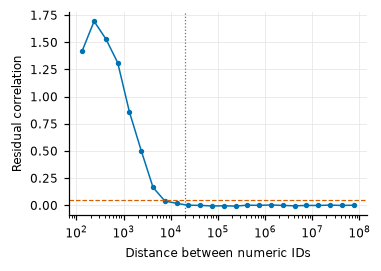

In [5]:


def oof_by_arm(feature_set: str, arm_folds: dict[int, np.ndarray], subset: np.ndarray | None = None) -> np.ndarray:
    """Skor out-of-fold. Batas bin usia dihitung ulang dari data latih tiap lipatan."""
    index = np.arange(frame.height) if subset is None else np.flatnonzero(subset)
    columns = [c for c in FEATURE_SETS[feature_set] if c != "age_bin12"]
    base = frame.select(columns).to_numpy().astype(np.float32)[index]
    local_y, local_recency, runs = y[index], recency[index], []
    for seed, fold_values in arm_folds.items():
        local_folds, score = fold_values[index], np.zeros(len(index))
        for fold in np.unique(local_folds):
            test = local_folds == fold
            edges = fit_age_edges(local_recency[~test], ctx.p.locked["features"]["age_bins"])
            X = np.column_stack([base, np.digitize(local_recency, edges).astype(np.float32)])
            score[test] = pilot_model(seed).fit(X[~test], local_y[~test]).predict_proba(X[test])[:, 1]
        runs.append(score)
    return np.mean(runs, axis=0)


baseline_oof = oof_by_arm("B2", folds["A1_random"], subset=is_dev_train)
residuals = y[is_dev_train] - baseline_oof
correlogram = residual_correlogram(ids[is_dev_train], residuals, seed=ctx.p.project["seed"])
autocorr_range = autocorrelation_range(correlogram)
primary = choose_block_width(cfg["id_block_widths"], autocorr_range)
if ctx.p.derived["primary_id_block_width"] is None:
    update_params(ctx, "derived.primary_id_block_width", primary)
    ctx = load_context(config_path)
print("jarak autokorelasi:", autocorr_range, "lebar terpilih:", primary, "tersimpan:", ctx.p.derived["primary_id_block_width"])
fig, ax = new_figure()
ax.semilogx([r["mid"] for r in correlogram], [r["corr"] for r in correlogram], marker="o", ms=2.5, lw=1, color="#0072B2")
ax.axhline(0.05, color="#D55E00", lw=0.8, ls="--"); ax.axvline(primary, color="#6E6E6E", lw=0.8, ls=":")
ax.set_xlabel("Distance between numeric IDs"); ax.set_ylabel("Residual correlation")
save_figure(fig, "fig_correlogram")

## 3. Performa per lengan validasi silang

In [6]:
scores = {arm: {fs: oof_by_arm(fs, folds[arm]) for fs in ("B2", "M_behav")} for arm in valid_arms}
all_mask = np.ones(frame.height, bool)
rows = []
for arm in valid_arms:
    for fs in ("B2", "M_behav"):
        rows.append({"arm": arm, "model": fs, **score_row(y, scores[arm][fs], strata, all_mask)})
cv_table = pd.DataFrame(rows)
primary_arm = f"A3_idblock_{ctx.p.derived['primary_id_block_width']}"
cv_table.loc[:, ["arm", "model", "n", "n_pos", "ap_all", "ap_5-19", "ap_20+", "base_5-19"]]

,arm,model,n,n_pos,ap_all,ap_5-19,ap_20+,base_5-19
0,A1_random,B2,77534,2232,0.168020,0.157772,0.262289,0.02685
1,A1_random,M_behav,77534,2232,0.425248,0.396567,0.628797,0.02685
2,A2_artifact,B2,77534,2232,0.161055,0.152213,0.237185,0.02685
3,A2_artifact,M_behav,77534,2232,0.415980,0.389587,0.605002,0.02685
4,A3_idblock_5000,B2,77534,2232,0.159347,0.149986,0.254695,0.02685
5,A3_idblock_5000,M_behav,77534,2232,0.422221,0.394298,0.628874,0.02685
6,A3_idblock_20000,B2,77534,2232,0.152812,0.151571,0.235052,0.02685
7,A3_idblock_20000,M_behav,77534,2232,0.382668,0.354634,0.614584,0.02685
8,A3_idblock_100000,B2,77534,2232,0.149434,0.147670,0.235287,0.02685
9,A3_idblock_100000,M_behav,77534,2232,0.386366,0.358368,0.616515,0.02685


## 4. Tambahan AP fitur perilaku dan H2a

H2a: rasio tambahan AP (A1 / A3 primer) pada stratum 5–19.

In [7]:
mask_519 = strata == "5-19"
clusters = id_block_groups(ids, ctx.p.derived["primary_id_block_width"])


def gain(arm: str, idx: np.ndarray) -> float:
    return average_precision_score(y[idx], scores[arm]["M_behav"][idx]) - average_precision_score(y[idx], scores[arm]["B2"][idx])


def ratio_metric(idx: np.ndarray) -> float:
    kept = idx[mask_519[idx]]
    if y[kept].sum() == 0:
        return float("nan")
    denominator = gain(primary_arm, kept)
    return float("nan") if denominator <= 0 else gain("A1_random", kept) / denominator


whole = np.flatnonzero(mask_519)
gains = {arm: gain(arm, whole) for arm in valid_arms}
ratio = gains["A1_random"] / gains[primary_arm] if primary_arm in gains and gains[primary_arm] > 0 else float("nan")
ratio_ci = paired_cluster_bootstrap(lambda idx: ratio_metric(idx) - 1.0, clusters, reps, ctx.p.project["seed"])
print("tambahan AP per lengan (5-19):", {k: round(v, 4) for k, v in gains.items()})
print("rasio A1/A3:", round(ratio, 3), "CI rasio:", round(ratio_ci["low"] + 1, 3), round(ratio_ci["high"] + 1, 3), "p:", round(ratio_ci["p_one_sided"], 4))

tambahan AP per lengan (5-19): {'A1_random': 0.2388, 'A2_artifact': 0.2374, 'A3_idblock_5000': 0.2443, 'A3_idblock_20000': 0.2031, 'A3_idblock_100000': 0.2107, 'A3s_signature': 0.2367}
rasio A1/A3: 1.176 CI rasio: 1.032 1.33 p: 0.0


## 5. Lengan forward tahap pengembangan

Train `w0–w1`, test `w2`. Model memakai konfigurasi pilot supaya audit tidak bergantung pada tuning.

In [8]:
data = load_stage(ctx, "dev", 60)
forward = {fs: pilot_scores(fs, data.train, [data.test, data.f1], ctx) for fs in ("B2", "M_behav")}
forward_rows = []
for arm in FORWARD_ARMS:
    test_frame, index = (data.f1, 1) if arm == "F1_forward" else (data.test, 0)
    fy, mask = test_frame["is_gone"].to_numpy().astype(int), arm_mask(data.train, test_frame, arm, ctx)
    for fs in ("B2", "M_behav"):
        forward_rows.append({"arm": arm, "model": fs, **score_row(fy, forward[fs][index], test_frame["stratum"].to_numpy(), mask)})
forward_table = pd.DataFrame(forward_rows)
audit = pd.concat([cv_table, forward_table], ignore_index=True)
save_table(audit, "tab_split_audit", "Measured performance per split arm, development stage (observed label)")
forward_table[["arm", "model", "n", "n_pos", "ap_all", "ap_5-19", "ap_20+", "base_5-19"]]

,arm,model,n,n_pos,ap_all,ap_5-19,ap_20+,base_5-19
0,F1_forward,B2,40918,1014,0.094419,0.067268,0.200132,0.020693
1,F1_forward,M_behav,40918,1014,0.248666,0.128754,0.642753,0.020693
2,F2_forward_new_accounts,B2,22095,560,0.078911,0.072324,0.142499,0.024230
3,F2_forward_new_accounts,M_behav,22095,560,0.193151,0.170317,0.502898,0.024230
4,F3_forward_batch_excluded,B2,19102,421,0.071686,0.065643,0.130904,0.020997
5,F3_forward_batch_excluded,M_behav,19102,421,0.165796,0.140330,0.482124,0.020997


selisih AP 5-19 tiap lengan CV terhadap F2 pengembangan: {'A1_random': 0.2262, 'A2_artifact': 0.2193, 'A3_idblock_5000': 0.224, 'A3_idblock_20000': 0.1843, 'A3_idblock_100000': 0.1881, 'A3s_signature': 0.2197}


1176

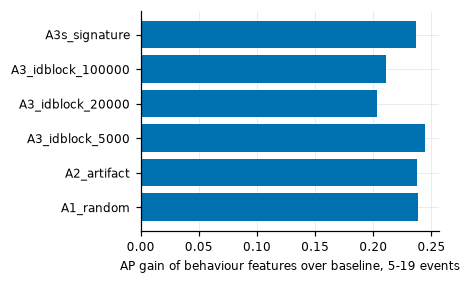

In [9]:
ref = forward_table.set_index(["arm", "model"]).loc[("F2_forward_new_accounts", "M_behav"), "ap_5-19"]
distance = {arm: float(cv_table[(cv_table.arm == arm) & (cv_table.model == "M_behav")]["ap_5-19"].iloc[0] - ref) for arm in valid_arms}
print("selisih AP 5-19 tiap lengan CV terhadap F2 pengembangan:", {k: round(v, 4) for k, v in distance.items()})
fig, ax = new_figure(height=2.6)
names = list(gains)
ax.barh(names, [gains[n] for n in names], color="#0072B2")
ax.set_xlabel("AP gain of behaviour features over baseline, 5-19 events")
save_figure(fig, "fig_split_bias")
summary = {"gains_5_19": gains, "ratio_a1_a3": ratio, "ratio_ci": [ratio_ci["low"] + 1, ratio_ci["high"] + 1], "ratio_p": ratio_ci["p_one_sided"], "distance_to_f2_dev": distance, "primary_width": ctx.p.derived["primary_id_block_width"], "autocorrelation_range": autocorr_range, "valid_arms": valid_arms, "cv_ap_5_19": {arm: float(cv_table[(cv_table.arm == arm) & (cv_table.model == "M_behav")]["ap_5-19"].iloc[0]) for arm in valid_arms}}
(ctx.paths.results / "split_audit_dev.json").write_text(json.dumps(summary, indent=2) + "\n")

## Ringkasan & cek

In [10]:
reported = set(cv_table["arm"])
degenerate = set(diagnostics.loc[diagnostics["is_degenerate"], "arm"])
checks.add("Q15", not (reported & degenerate), f"lengan degeneratif: {sorted(degenerate)}")
checks.add("Q16", ctx.p.derived["primary_id_block_width"] in cfg["id_block_widths"], str(ctx.p.derived["primary_id_block_width"]))
checks.add("Q17", "w3" not in frame["week"].unique().to_list(), "tanpa w3")
checks.raise_if_failed()
write_numbers({"primary_id_block_width": ctx.p.derived["primary_id_block_width"], "ratio_h2a": ratio})
print(run.finish(n_rows=frame.height, n_pos=int(y.sum())))

[LULUS] Q15: lengan degeneratif: []
[LULUS] Q16: 20000
[LULUS] Q17: tanpa w3
{'notebook': '09_split_audit', 'finished_at_utc': '2026-11-10T11:39:23+00:00', 'git_commit': 'f04dbd3', 'duration_seconds': 211.2, 'counts': {'n_rows': 77534, 'n_pos': 2232}}
